In [19]:
%pylab inline

import os
from astropy.table import Table, vstack
import astropy.io.fits as pyfits

import matplotlib
import matplotlib.patches as mpatches

from lsst.daf.persistence import Butler
butler16 = Butler('./homeDir/data/hsc_ssp/dr1/s16a/data/s16a_wide2/')
butler18 = Butler('./homeDir/data/hsc_ssp/dr2/s18a/data/test/s18a_wide_revpsf/')
butler19 = Butler('./homeDir/data/hsc_ssp/dr3/s19a/data/s19a_wide/')
import lsst.afw.image as afwImage
import lsst.afw.table as afwTable
import lsst.afw.image as afwImage
import lsst.afw.display as afwDisplay
afwDisplay.setDefaultBackend('matplotlib')
display1 = afwDisplay.getDisplay(frame=1)
display2 = afwDisplay.getDisplay(frame=2)
display3 = afwDisplay.getDisplay(frame=3)
display4 = afwDisplay.getDisplay(frame=4)
display5 = afwDisplay.getDisplay(frame=5)
import lsst.afw.geom as afwGeom
from lsst.meas.base.noiseReplacer import NoiseReplacerConfig,NoiseReplacer
import lsst.analysis.deblender as deblender


import astropy.io.ascii as ascii


nameNchild = "deblend_nchild"

def mtvShowObj(expo,srcs,objId,display):
    sss=srcs.find(objId)
    extU=afwGeom.Extent2I(50,50)
    boxU=afwGeom.Box2I(afwGeom.Point2I(sss.getCentroid())-extU,2*extU)
    sss
    boxU.clip(expo.getBBox())
    expShow=expo[boxU]
    display.mtv(expShow)
    """
    fam=deblender.Families(srcs,nChildMin=0)
    srcShow=fam.find(objId,matchRadius=10)
    with display.Buffering(): 
        for ssShow in srcShow:
            label='+'
            display.dot(label,ssShow[0].getX(),ssShow[0].getY(), size=3, ctype=afwDisplay.RED)
    """
    return

def replaceNoise(exposure,sources,objId):
    footprints  = {measRecord.getId(): (measRecord.getParent(), measRecord.getFootprint())
                  for measRecord in sources}
    noiConfig   =   NoiseReplacerConfig()
    noiseReplacer=  NoiseReplacer(noiConfig, exposure, footprints)
    noiseReplacer.insertSource(objId)
    return exposure

Populating the interactive namespace from numpy and matplotlib


/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/IPython/core/magics/pylab.py:160: UserWarning: pylab import has clobbered these variables: ['vstack']
`%matplotlib` prevents importing * from pylab and numpy
  "\n`%matplotlib` prevents importing * from pylab and numpy"


# Comaprison between S16 S18 and S19

# Difference 1: Detection number difference
![](wrkDir/s18-2/plot/spacial/num_mag.png)

### The left panel is the total number in S16A FDFC region with only magnitude cut and pixel flag masks. WL cut further appied and the total number is shown in the right panel. 

# Pixels Masks

```sql
NOT meas_ireprocess.i_deblend_skipped                   AND
NOT meas_ireprocess.i_sdsscentroid_flag                 AND
NOT meas_ireprocess.i_pixelflags_edge                   AND
NOT meas_ireprocess.i_pixelflags_interpolatedcenter     AND
NOT meas_ireprocess.i_pixelflags_saturatedcenter        AND
NOT meas_ireprocess.i_pixelflags_crcenter               AND
NOT meas_ireprocess.i_pixelflags_bad                    AND
NOT meas_ireprocess.i_pixelflags_suspectcenter          AND
NOT meas_ireprocess.i_pixelflags_clipped                AND
meas_ireprocess.i_detect_isprimary                      AND
NOT meas_ireprocess.i_hsmshaperegauss_flag              AND
meas.i_extendedness_value != 0                          AND
meas_ireprocess.i_hsmshaperegauss_sigma != 'NaN'
```
* BAD 0
* SAT 1
* **INTRP 2**
* **CR 3**
* EDGE 4
* DETECTED 5
* DETECTED_NEGATIVE 6
* SUSPECT 7
* NO_DATA 8
* BRIGHT_OBJECT 9
* CLIPPED 10
* CROSSTALK 11
* **INEXACT_PSF 12**
* NOT_DEBLENDED 13
* **REJECTED 14**
* **SENSOR_EDGE 15**
* UNMASKEDNAN 16

![](wrkDir/s18-2/plot/spacial/s18-ratio-numMap-obs.png)
![](wrkDir/s18-2/plot/spacial/s18-ratio-hist-obs.png)


![](wrkDir/s18-2/plot/spacial/s19-ratio-numMap-obs.png)
![](wrkDir/s18-2/plot/spacial/s19-ratio-hist-obs.png)

# Difference 2: Measurement difference

## snr-res histogram after WL cut

![](galDis-s16-s18-s19-append.png)

```python
match   =   smatch.match(data16['ra'],data16['dec'],0.4/3600.,\
    data18['ra'],data18['dec'],maxmatch=1)
index   =   np.unique(match['i1'],return_index=True)[1]
match   =   match[index]
```

<img src=galMatch.png width="500"/>

* For each galaxy in S18A (red), find the closest galaxy within 0.4 arcsec.
* For each galaxy in S16A (blue) having multiple matches, only randomly keep one match.

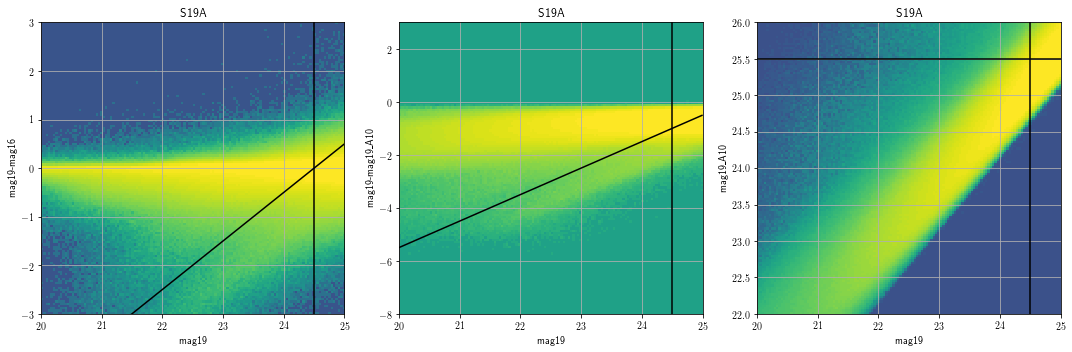

In [23]:
#dat18=pyfits.getdata('./wrkDir/s18-2/plot/compare/hist2d-dmag-mag_s18-all-all.fits')
dat19=pyfits.getdata('./wrkDir/s18-2/plot/compare/hist2d-dmag16-mag_s19-all-all.fits')
dat19dmagA10=pyfits.getdata('./wrkDir/s18-2/plot/compare/hist2d-dmagA10-mag_s19-all-all.fits')
dat19magA10=pyfits.getdata('./wrkDir/s18-2/plot/compare/hist2d-magA10-mag_s19-all-all.fits')
def makeMagdMagPlot(data,ax,title,xmin,xmax,ymin,ymax):
    dextent =   [xmin,xmax,ymin,ymax]
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ymin,ymax)
    bdry    =   np.percentile(data,np.arange(1,99,1))
    norm2   =   matplotlib.colors.BoundaryNorm(bdry,ncolors=256)
    im      =   ax.imshow(data,extent=dextent,norm=norm2,origin='lower',aspect='auto')
    ax.set_title(title)
    plt.grid()
    return
fig     =   plt.figure(figsize=(15, 5))

ax      =   fig.add_subplot(1,3,1)
makeMagdMagPlot(dat19,ax,'S19A',xmin=20,xmax=25,ymin=-3,ymax=3)
ax.set_xlabel('mag19')
ax.set_ylabel('mag19-mag16')
x=np.arange(20,25.,0.01)
y=x-24.5
ax.plot(x,y,c='black')
axvline(24.5,c='black')

ax      =   fig.add_subplot(1,3,2)
makeMagdMagPlot(dat19dmagA10,ax,'S19A',xmin=20,xmax=25,ymin=-8,ymax=3)
ax.set_xlabel('mag19')
ax.set_ylabel('mag19-mag19\_A10')
x=np.arange(20,25.,0.01)
y=x-25.5
ax.plot(x,y,c='black')
axvline(24.5,c='black')

ax      =   fig.add_subplot(1,3,3)
makeMagdMagPlot(dat19magA10,ax,'S19A',xmin=20,xmax=25,ymin=22,ymax=26)
axvline(24.5,c='black')
axhline(25.5,c='black')
ax.set_xlabel('mag19')
ax.set_ylabel('mag19\_A10')

plt.tight_layout()
plt.show()

In [1]:
display1 = afwDisplay.getDisplay(frame=1)
hist=afwImage.ImageD('./wrkDir/s18-2/plot/compare/hist2d-dmag-mag_s18-all-all.fits')
display1.mtv(hist)

display2 = afwDisplay.getDisplay(frame=2)
hist=afwImage.ImageD('./wrkDir/s18-2/plot/compare/hist2d-dmagA10-mag_s19-all-all.fits')
display2.mtv(hist)

display3 = afwDisplay.getDisplay(frame=3)
hist=afwImage.ImageD('./wrkDir/s18-2/plot/compare/hist2d-magA10-mag_s19-all-all.fits')
display3.mtv(hist)

![](wrkDir/s18-2/plot/galDis-s19-final/galDis2D-final-mag-24.5-scat.png)
![](wrkDir/s18-2/plot/galDis-s19-final/galDis2D-final-magA10-25.5-scat.png)

# Case 1: unrecongnized potential blending !

In [16]:
cat=Table.read('wrkDir/exfaGalAll-noiRep-srcInser/s16/cat-0.csv')

In [122]:
img16=pyfits.getdata('wrkDir/exfaGalAll-noiRep-srcInser/s16/gal-0.fits')
img18=pyfits.getdata('wrkDir/exfaGalAll-noiRep-srcInser/s18/gal-0.fits')
img19=pyfits.getdata('wrkDir/exfaGalAll-noiRep-srcInser/s19/gal-0.fits')

imgO16=pyfits.getdata('wrkDir/exfaGalAll/s16/gal-0.fits')
imgO18=pyfits.getdata('wrkDir/exfaGalAll/s18/gal-0.fits')
imgO19=pyfits.getdata('wrkDir/exfaGalAll/s19/gal-0.fits')

mskO16=pyfits.getdata('wrkDir/exfaGalAll/s16/msk-0.fits').astype(int)
mskO18=pyfits.getdata('wrkDir/exfaGalAll/s18/msk-0.fits').astype(int)
mskO19=pyfits.getdata('wrkDir/exfaGalAll/s19/msk-0.fits').astype(int)

msk16=(np.bitwise_and(mskO16,32))*1.
msk18=(np.bitwise_and(mskO18,32))*1.
msk19=(np.bitwise_and(mskO19,32))*1.

bad16=((mskO16!=0) & (mskO16!=32))*10.
bad18=((mskO18!=0) & (mskO18!=32))*10.
bad19=((mskO19!=0) & (mskO19!=32))*10.

imgO162=pyfits.getdata('wrkDir/exfaGalAll/s16/gal-1.fits')
imgO182=pyfits.getdata('wrkDir/exfaGalAll/s18/gal-1.fits')
imgO192=pyfits.getdata('wrkDir/exfaGalAll/s19/gal-1.fits')

msk162=pyfits.getdata('wrkDir/exfaGalAll/s16/msk-1.fits').astype(int)
msk182=pyfits.getdata('wrkDir/exfaGalAll/s18/msk-1.fits').astype(int)
msk192=pyfits.getdata('wrkDir/exfaGalAll/s19/msk-1.fits').astype(int)

import astropy.io.ascii as ascii
mat16=ascii.read('wrkDir/exfaGalAll/s16/mat-0.csv')
mat18=ascii.read('wrkDir/exfaGalAll/s18/mat-0.csv')
mat19=ascii.read('wrkDir/exfaGalAll/s19/mat-0.csv')

def makePlot3(i):
    ss=cat[i]
    print(ss['ra'],ss['dec'],ss['TPid'])
    mm16=mat16[mat16['id1']==i]
    mm18=mat18[mat18['id1']==i]
    mm19=mat19[mat19['id1']==i]
    def drawCircle(mms):
        for ms in mms:
            if ms['dx']**2.+ms['dy']**2.<150.:
                mxy=(ngrid//2+ms['dx'],ngrid//2+ms['dy'])
                mrg=min(ms['traceR']/0.168,ngrid//2)
                mclr =   cmap(norm(ms['mag']))
                mcir =   mpatches.Circle(mxy,radius=mrg,ls='-',facecolor='None',edgecolor=mclr,lw=3.)
                ax.add_patch(mcir)
        return
    
    
    ngrid=64
    xy  =   (ngrid//2,ngrid//2)
    cmap    =   plt.cm.Paired
    norm    =   matplotlib.colors.Normalize(vmin=21,vmax=25.)
    mappable=   plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    mappable.set_array([])

    fig =   plt.figure(figsize=(15, 11))

    ax  =   fig.add_subplot(2,3,1)
    ax.set_title('S16A')
    drawCircle(mm16)
    ax.imshow(img16[i],origin='lower',cmap='Greys_r')

    ax  =   fig.add_subplot(2,3,2)
    ax.set_title('S18A')
    drawCircle(mm18)
    ax.imshow(img18[i],origin='lower',cmap='Greys_r')

    ax  =   fig.add_subplot(2,3,3)
    ax.set_title('S19A')
    drawCircle(mm19)
    ax.imshow(img19[i],origin='lower',cmap='Greys_r')

    ax  =   fig.add_subplot(2,3,4)
    drawCircle(mm16)
    ax.imshow(msk16[i]+bad16[i],origin='lower',cmap='Greys_r')

    ax  =   fig.add_subplot(2,3,5)
    drawCircle(mm18)
    ax.imshow(msk18[i]+bad18[i],origin='lower',cmap='Greys_r')

    ax  =   fig.add_subplot(2,3,6)
    drawCircle(mm19)
    ax.imshow(msk19[i]+bad19[i],origin='lower',cmap='Greys_r')
    
    cbar_ax     =   fig.add_axes([0.12, 0.1, 0.78, 0.01])
    fig.colorbar(mappable,cbar_ax,orientation='horizontal')
    plt.show()
    return fig

def makePlot4():
    bg16=[]
    bg18=[]
    bg19=[]
    for j in range(len(il)):
        i=il[j]
        mask1=(msk19[i]==0)& (msk18[i]==0) & (msk16[i]==0)
        bg16.extend(imgO16[i][mask1])
        bg18.extend(imgO18[i][mask1])
        bg19.extend(imgO19[i][mask1])
        mask2=(msk192[i]==0)& (msk182[i]==0) & (msk162[i]==0)
        bg16.extend(imgO162[i][mask2])
        bg18.extend(imgO182[i][mask2])
        bg19.extend(imgO192[i][mask2])

    h,g=np.histogram(bg16,30)
    ave=np.average(bg16)
    axvline(ave,c='red',ls='--')
    plt.plot(g[:-1],h,'--',label='s16A',c='red')
    h,g=np.histogram(bg18,g)
    ave=np.average(bg18)
    axvline(ave,c='blue',ls='-')
    plt.plot(g[:-1],h,'-',label='s18A',c='blue')
    h,g=np.histogram(bg19,g)
    ave=np.average(bg19)
    axvline(ave,c='black',ls='-.')
    plt.plot(g[:-1],h,'-.',label='s19A',c='black')
    plt.xlabel('pixel value')
    plt.ylabel('num')
    plt.yscale('log')
    plt.legend()
    return

240.56146077630922 43.14520925893637 16007200


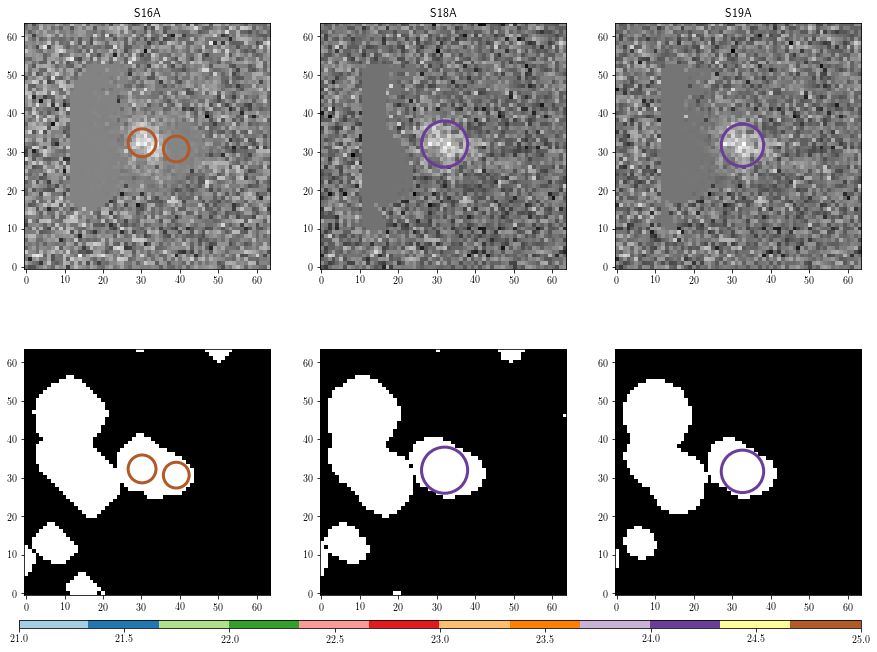

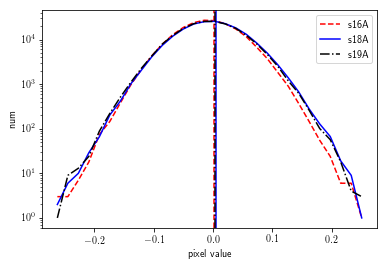

In [9]:
from IPython.display import clear_output
import time
j=0
il=[3,4,12,13,16,20,21,25,27,32,33,37,40,0,2,41,43,48,50,10,11,18,24,52,53,54,55,56,57,58,59,60,61,62,63,67,68,70,71,73,74]
i=il[j]
fig=makePlot3(i)
makePlot4()

* larger resolution
* brighter magnitude
* more sources (\# S19 < \# S16)

In [17]:
il=[3,4,12,13,16,20,21,25,27,32,33,37,40,0,2,41,43,48,50,10,11,18,24,52,53,54,55,56,57,58,59,60,61,62,63,67,68,70,71,73,74]

catDis=cat[il]
tpIdSet=list(set(catDis['TPid']))
ii=3
catTest=catDis[ii]
TPid=catTest['TPid']
dataId = {'filter': 'HSC-I', 'tract': TPid//1000, 'patch': '%d,%d' %(TPid%1000/100,TPid%100%100)}

expN16 = butler16.get('deepCoadd_calexp_filename', **dataId)[0].split('-results/')[1]
expN16=os.path.join('/work/xiangchong.li/superonionGW/code/G3sim-s18a/notebook/susGal/homeDir/data/hsc_ssp/dr1/s16a/data/s16a_wide2/deepCoadd',expN16)
exp16=afwImage.ExposureF(expN16)
src16=butler16.get('deepCoadd_meas',**dataId)

exp19 = butler19.get('deepCoadd_calexp', **dataId)
src19=butler19.get('deepCoadd_meas',**dataId)

In [ ]:
mtvShowObj(exp16,src16,catTest['object_id16'],display1)
mtvShowObj(exp19,src19,catTest['object_id19'],display2)
exp16NR=replaceNoise(exp16,src16,catTest['object_id16'])
exp19NR=replaceNoise(exp19,src19,catTest['object_id19'])
mtvShowObj(exp16NR,src16,catTest['object_id16'],display3)
mtvShowObj(exp19NR,src19,catTest['object_id19'],display4)

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:36: FutureWarning: Call to deprecated function (or staticmethod) Extent2I. (Replaced by lsst.geom.Extent2I (will be removed before the release of v20.0))
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:37: FutureWarning: Call to deprecated function (or staticmethod) Point2I. (Replaced by lsst.geom.Point2I (will be removed before the release of v20.0))
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:37: FutureWarning: Call to deprecated function (or staticmethod) Box2I. (Replaced by lsst.geom.Box2I (will be removed before the release of v20.0))


# Case 2: No difference in Dections

245.3816870390777 43.12196037186333 15831108


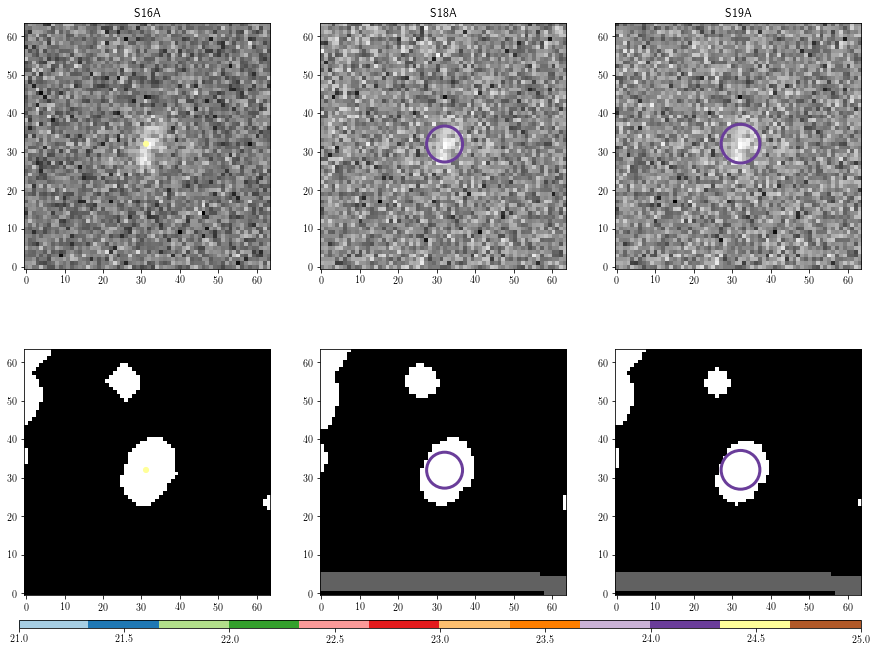

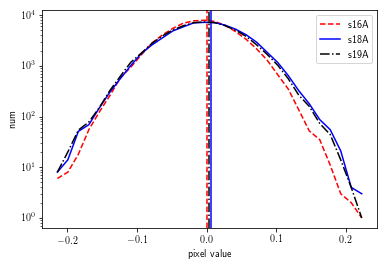

In [123]:
j=1
il=[1,29,31,35,37,39,42,44,45,46,47,49,64,64,65]
i=il[j]
fig=makePlot3(i)
makePlot4()

In [ ]:
il=[1,29,31,35,37,39,42,44,45,46,47,49,64,64,65]
catDis=cat[il]
tpIdSet=list(set(catDis['TPid']))
ii=3
catTest=catDis[ii]
TPid=catTest['TPid']
dataId = {'filter': 'HSC-I', 'tract': TPid//1000, 'patch': '%d,%d' %(TPid%1000/100,TPid%100%100)}

expN16 = butler16.get('deepCoadd_calexp_filename', **dataId)[0].split('-results/')[1]
expN16=os.path.join('/work/xiangchong.li/superonionGW/code/G3sim-s18a/notebook/susGal/homeDir/data/hsc_ssp/dr1/s16a/data/s16a_wide2/deepCoadd',expN16)
exp16=afwImage.ExposureF(expN16)
src16=butler16.get('deepCoadd_meas',**dataId)

exp19 = butler19.get('deepCoadd_calexp', **dataId)
src19=butler19.get('deepCoadd_meas',**dataId)

mtvShowObj(exp16,src16,catTest['object_id16'],display1)
mtvShowObj(exp19,src19,catTest['object_id19'],display2)
exp16NR=replaceNoise(exp16,src16,catTest['object_id16'])
exp19NR=replaceNoise(exp19,src19,catTest['object_id19'])
mtvShowObj(exp16NR,src16,catTest['object_id16'],display3)
mtvShowObj(exp19NR,src19,catTest['object_id19'],display4)

# Case 3 Extreme Case

0.13
244.36246659401098 43.433764958215015 16009302


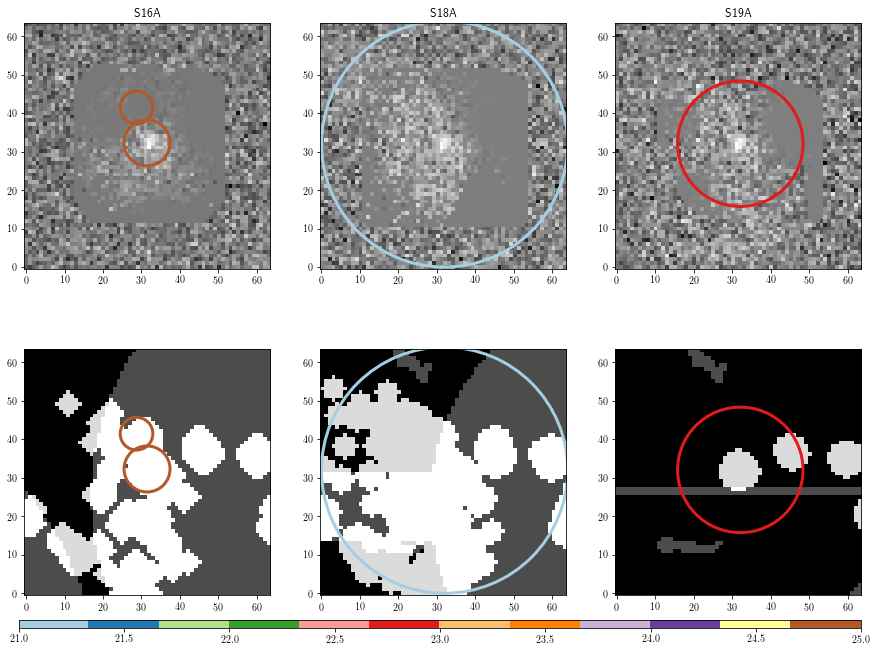

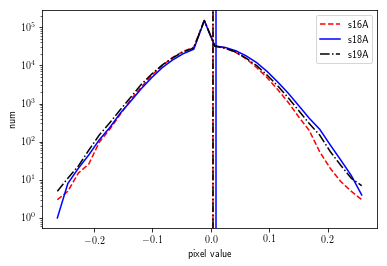

In [11]:
il=np.where((cat['mag16']-cat['mag'])>2.5)[0]
print(len(il)/len(cat))
j=2
i=il[j]
makePlot3(i)
makePlot4()

In [12]:
a=pyfits.getdata('./wrkDir/database/compare/scat-s16-unmatch-s18.fits')
b=pyfits.getdata('./wrkDir/database/compare/scat-s18-unmatch-s16.fits')
a2=pyfits.getdata('./wrkDir/database/compare/scat-s16-unmatch-s19.fits')

In [13]:
maskA=(a['mag']<19)&(a['res']>0.3)&(a['logb']<-0.38)&(a['TPid']==9696502)
maskB=(b['mag']<19)&(b['res']>0.3)&(b['logb']<-0.38)&(b['TPid']==9696502)
maskA2=(a2['mag']<19)&(a2['res']>0.3)&(a2['logb']<-0.38)&(a2['TPid']==9696502)
aM=a[maskA]
bM=b[maskB]
aM2=a2[maskA2]

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:1: RuntimeWarning: invalid value encountered in less
  """Entry point for launching an IPython kernel.
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:2: RuntimeWarning: invalid value encountered in less
  
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:3: RuntimeWarning: invalid value encountered in less
  This is separate from the ipykernel package so we can avoid doing imports until


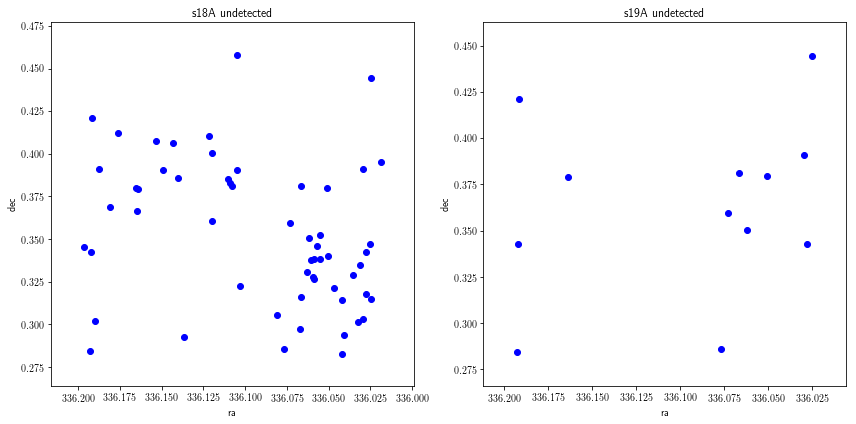

In [14]:
fig=    plt.figure(figsize=(12, 6))
ax =    fig.add_subplot(1,2,1)
ax.scatter(aM['ra'],aM['dec'],c='blue')
#ax.scatter(bM['ra'],bM['dec'],c='red')
x0,x1 = ax.get_xlim();ax.set_xlim(x1, x0)
ax.set_xlabel('ra')
ax.set_ylabel('dec')
ax.set_title('s18A undetected')
ax =    fig.add_subplot(1,2,2)
ax.scatter(aM2['ra'],aM2['dec'],c='blue')
#ax.scatter(bM['ra'],bM['dec'],c='red')
x0,x1 = ax.get_xlim();ax.set_xlim(x1, x0)
ax.set_xlabel('ra')
ax.set_ylabel('dec')
ax.set_title('s19A undetected')
plt.tight_layout()

### This left (right) panel shows the galaxies in S16A WL with $mag \lt 19$ which do not have corresponding match within 0.4 arcsec in S18A ( S19A)


![](undetect-brightGal-1.png)

![](undetect-brightGal-2.png)

Text(0.5, 0, 'R (arcmin)')

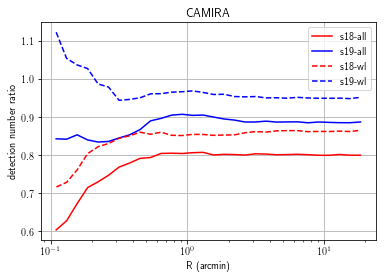

In [15]:
d16=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-CAMIRA-detect-s16.csv')
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-CAMIRA-detect-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-CAMIRA-detect-s19.csv')
plt.plot(d18['meanR'],d18['npairs']/d16['npairs'],c='red',label='s18-all')
plt.plot(d19['meanR'],d19['npairs']/d16['npairs'],c='blue',label='s19-all')
d16=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-detect-s16.csv')
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-detect-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-detect-s19.csv')
plt.plot(d18['meanR'],d18['npairs']/d16['npairs'],c='red',ls='--',label='s18-wl')
plt.plot(d19['meanR'],d19['npairs']/d16['npairs'],c='blue',ls='--',label='s19-wl')
plt.legend()
plt.grid()
plt.title('CAMIRA')
plt.xlabel('R (arcmin)')
plt.ylabel('detection number ratio')
plt.xscale('log')
plt.xlabel('R (arcmin)')

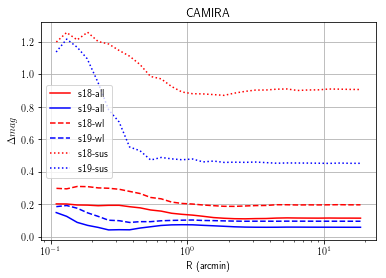

In [16]:
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-CAMIRA-mag-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-CAMIRA-mag-s19.csv')
plt.plot(d18['meanR'],d18['kappa'],c='red',label='s18-all')
plt.plot(d19['meanR'],d19['kappa'],c='blue',label='s19-all')
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-mag-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-mag-s19.csv')
plt.plot(d18['meanR'],d18['kappa'],c='red',ls='--',label='s18-wl')
plt.plot(d19['meanR'],d19['kappa'],c='blue',ls='--',label='s19-wl')
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-sus-CAMIRA-mag-ncor-all-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-sus-CAMIRA-mag-ncor-all-s19.csv')
plt.plot(d18['meanR'],d18['kappa'],c='red',ls=':',label='s18-sus')
plt.plot(d19['meanR'],d19['kappa'],c='blue',ls=':',label='s19-sus')
plt.title('CAMIRA')
plt.xlabel('R (arcmin)')
plt.ylabel(r'$\Delta mag$')
plt.xscale('log')
plt.grid()
plt.legend()

Text(0.5, 0, 'R (arcmin)')

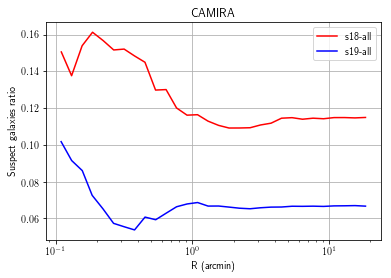

In [17]:
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-sus-CAMIRA-susRatio-ncor-all-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-sus-CAMIRA-susRatio-ncor-all-s19.csv')
d18wl=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-susRatio-ncor-all-s18.csv')
d19wl=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-susRatio-ncor-all-s19.csv')
plt.plot(d18['meanR'],d18['npairs']/d18wl['npairs'],c='red',label='s18-all')
plt.plot(d19['meanR'],d19['npairs']/d19wl['npairs'],c='blue',label='s19-all')

plt.legend()
plt.grid()
plt.title('CAMIRA')
plt.xlabel('R (arcmin)')
plt.ylabel('Suspect galaxies ratio')
plt.xscale('log')
plt.xlabel('R (arcmin)')

Text(0.5, 0, 'R (arcmin)')

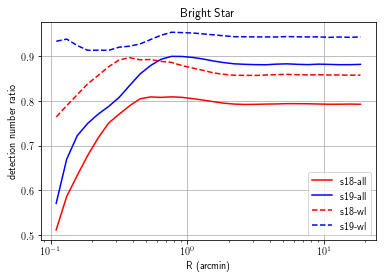

In [18]:
d16=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-star-detect-s16.csv')
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-star-detect-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-star-detect-s19.csv')
plt.plot(d18['meanR'],d18['npairs']/d16['npairs'],c='red',label='s18-all')
plt.plot(d19['meanR'],d19['npairs']/d16['npairs'],c='blue',label='s19-all')

d16=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-detect-s16.csv')
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-detect-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-detect-s19.csv')
plt.plot(d18['meanR'],d18['npairs']/d16['npairs'],c='red',ls='--',label='s18-wl')
plt.plot(d19['meanR'],d19['npairs']/d16['npairs'],c='blue',ls='--',label='s19-wl')
plt.legend()
plt.grid()
plt.title('Bright Star')
plt.xlabel('R (arcmin)')
plt.ylabel('detection number ratio')
plt.xscale('log')
plt.xlabel('R (arcmin)')

Text(0.5, 0, 'R (arcmin)')

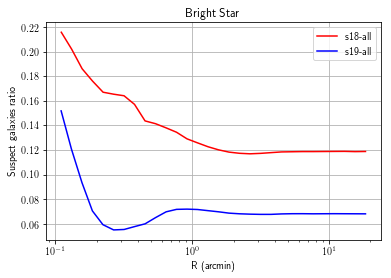

In [19]:
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-sus-star-susRatio-mag-all-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-sus-star-susRatio-mag-all-s19.csv')
d18wl=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-susRatio-mag-all-s18.csv')
d19wl=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-susRatio-mag-all-s19.csv')
plt.plot(d18['meanR'],d18['npairs']/d18wl['npairs'],c='red',label='s18-all')
plt.plot(d19['meanR'],d19['npairs']/d19wl['npairs'],c='blue',label='s19-all')

plt.legend()
plt.grid()
plt.title('Bright Star')
plt.xlabel('R (arcmin)')
plt.ylabel('Suspect galaxies ratio')
plt.xscale('log')
plt.xlabel('R (arcmin)')

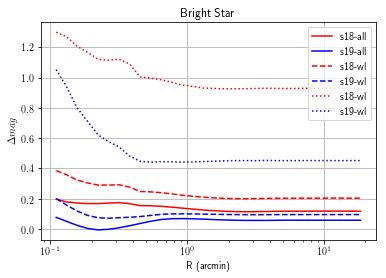

In [20]:
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-star-mag-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-all-star-mag-s19.csv')
plt.plot(d18['meanR'],d18['kappa'],c='red',label='s18-all')
plt.plot(d19['meanR'],d19['kappa'],c='blue',label='s19-all')
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-mag-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-mag-s19.csv')
plt.plot(d18['meanR'],d18['kappa'],c='red',ls='--',label='s18-wl')
plt.plot(d19['meanR'],d19['kappa'],c='blue',ls='--',label='s19-wl')
d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-sus-star-mag-mag-all-s18.csv')
d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-sus-star-mag-mag-all-s19.csv')
plt.plot(d18['meanR'],d18['kappa'],c='red',ls=':',label='s18-wl')
plt.plot(d19['meanR'],d19['kappa'],c='blue',ls=':',label='s19-wl')
plt.xlabel('R (arcmin)')
plt.ylabel(r'$\Delta mag$')
plt.xscale('log')
plt.title('Bright Star')
plt.grid()
plt.legend()

Text(0.5, 0, 'mag')

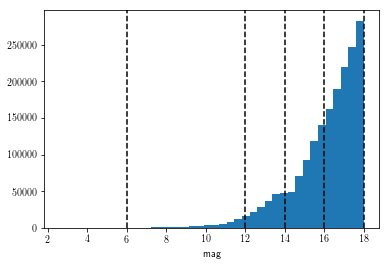

In [21]:
import astropy.io.fits as pyfits
a=pyfits.getdata('wrkDir/database/GAIA_Stars.fits',ext=1)
hist,grid,fig=plt.hist(a['G_Gaia'],40)
cutlist=[6,12,14,16,18]
for ic in cutlist:
    axvline(ic,c='black',ls='--')
plt.xlabel('mag')

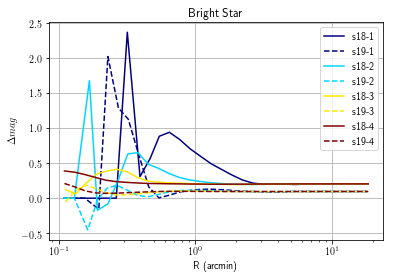

In [22]:
colors = plt.cm.jet(np.linspace(0,1,4))
for ig in range(4):
    d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-mag-mag-g%s-s18.csv' %ig)
    d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-mag-mag-g%s-s19.csv' %ig)
    plt.plot(d18['meanR'],d18['kappa'],label='s18-%s' %(ig+1), color=colors[ig], ls='-')
    plt.plot(d19['meanR'],d19['kappa'],label='s19-%s' %(ig+1), color=colors[ig], ls='--')


plt.xlabel('R (arcmin)')
plt.ylabel(r'$\Delta mag$')
plt.xscale('log')
plt.title('Bright Star')
plt.grid()
plt.legend()

Text(0.5, 0, 'R (arcmin)')

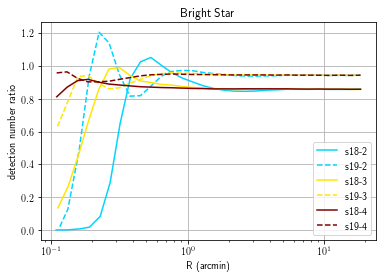

In [23]:
colors = plt.cm.jet(np.linspace(0,1,4))
for ig in range(1,4):
    d16=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-detect-mag-g%s-s16.csv' %ig)
    d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-detect-mag-g%s-s18.csv' %ig)
    d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-star-detect-mag-g%s-s19.csv' %ig)
    plt.plot(d18['meanR'],d18['npairs']/d16['npairs'],c=colors[ig],label='s18-%s' %(ig+1),ls='-')
    plt.plot(d19['meanR'],d19['npairs']/d16['npairs'],c=colors[ig],label='s19-%s' %(ig+1),ls='--')

plt.legend()
plt.grid()
plt.title('Bright Star')
plt.xlabel('R (arcmin)')
plt.ylabel('detection number ratio')
plt.xscale('log')
plt.xlabel('R (arcmin)')

Text(0.5, 0, 'ncor')

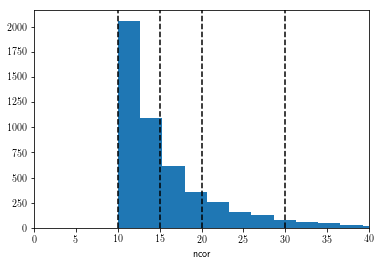

In [24]:
a=ascii.read('wrkDir/database/CAMIRA_S16A.csv')
hist,grid,fig=plt.hist(a['N_cor'],40)
plt.xlim(0,40)
cutlist=[10,15,20,30,80]
for ic in cutlist:
    axvline(ic,c='black',ls='--')
plt.xlabel('ncor')

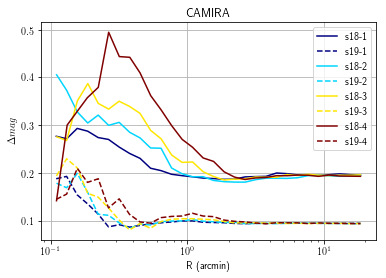

In [25]:
colors = plt.cm.jet(np.linspace(0,1,4))
for ig in range(4):
    d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-mag-ncor-g%s-s18.csv' %ig)
    d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-mag-ncor-g%s-s19.csv' %ig)
    plt.plot(d18['meanR'],d18['kappa'],label='s18-%s' %(ig+1), color=colors[ig], ls='-')
    plt.plot(d19['meanR'],d19['kappa'],label='s19-%s' %(ig+1), color=colors[ig], ls='--')

plt.xlabel('R (arcmin)')
plt.ylabel(r'$\Delta mag$')
plt.xscale('log')
plt.title('CAMIRA')

plt.grid()
plt.legend()

Text(0.5, 0, 'R (arcmin)')

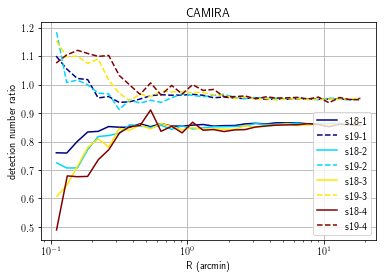

In [26]:
colors = plt.cm.jet(np.linspace(0,1,4))
for ig in range(4):
    d16=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-detect-ncor-g%s-s16.csv' %ig)
    d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-detect-ncor-g%s-s18.csv' %ig)
    d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-CAMIRA-detect-ncor-g%s-s19.csv' %ig)
    plt.plot(d18['meanR'],d18['npairs']/d16['npairs'],c=colors[ig],label='s18-%s' %(ig+1),ls='-')
    plt.plot(d19['meanR'],d19['npairs']/d16['npairs'],c=colors[ig],label='s19-%s' %(ig+1),ls='--')

plt.legend(loc='lower right')
plt.grid()
plt.title('CAMIRA')
plt.xlabel('R (arcmin)')
plt.ylabel('detection number ratio')
plt.xscale('log')
plt.xlabel('R (arcmin)')

Text(0.5, 0, 'mag')

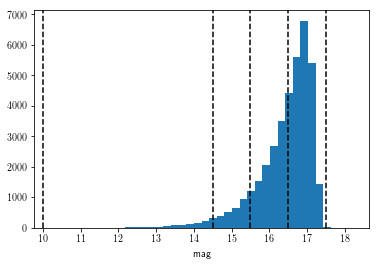

In [31]:
import astropy.io.fits as pyfits
a=ascii.read('wrkDir/database/Wang_S16A.csv')
hist,grid,fig=plt.hist(a['imag_model'],40)
cutlist=[10,14.5,15.5,16.5,17.5]
for ic in cutlist:
    axvline(ic,c='black',ls='--')
plt.xlabel('mag')

In [ ]:
colors = plt.cm.jet(np.linspace(0,1,4))
for ig in range(4):
    d18=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-Wang-mag-mag-g%s-s18.csv' %ig)
    d19=ascii.read('wrkDir/s18-2/plot/galCor/cor2PNK-wl-Wang-mag-mag-g%s-s19.csv' %ig)
    plt.plot(d18['meanR'],d18['kappa'],label='s18-%s' %(ig+1), color=colors[ig], ls='-')
    plt.plot(d19['meanR'],d19['kappa'],label='s19-%s' %(ig+1), color=colors[ig], ls='--')

plt.xlabel('R (arcmin)')
plt.ylabel(r'$\Delta mag$')
plt.xscale('log')
plt.title('Wang')

plt.grid()
plt.legend(loc='upper right')

# Solution

![](wrkDir/s18-2/plot/galDis-s18-final/galDis2D-final-magA10-25.9.png)

![](wrkDir/s18-2/plot/galDis-s18-final/galDis2D-final-magA10-25.8.png)

![](wrkDir/s18-2/plot/galDis-s18-final/galDis2D-final-magA10-25.7.png)

![](wrkDir/s18-2/plot/galDis-s18-final/galDis2D-final-magA10-25.6.png)

![](wrkDir/s18-2/plot/galDis-s18-final/galDis2D-final-magA10-25.5.png)

![](wrkDir/s18-2/plot/galDis-s18-final/galDis2D-final-magA10-25.4.png)

![](wrkDir/s18-2/plot/galDis-s18-final/galDis2D-final-magA10-25.3.png)